# Investigate Models

> **13.01.2025 -> moved this to Prod.**

> Melih Kara <br>
> 24/07/2023 <br>

This notebook describes the models that we use for our analysis. We visualize some of the model features as well as the computed interaction rates as functions of time and recoil energy. <br>
Finaly we have a comparison of the interaction rates with different isotopes. <br>

Uses `snewpy.__version__ == 1.4.1`

In [6]:
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

import sys
sys.path.insert(1, '/home/melih/SNAX/helper-scripts/')
import homogenise_plots as hm

In [7]:
import snax
import numpy as np
import os
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import pandas as pd

In [8]:
from snewpy.neutrino import Flavor
from snax.SnewpyWrapper import SnewpyModel
from snax.models import SnaxModel
from snax.interactions import Interactions
from snax.Simulations import SimulationInstructions, SimulateSignal
import astropy.units as u
from tqdm.notebook import tqdm

## re-initiated
xps.use('xenonnt')

line_styles = ['-', '--', '-.', ':', 'solid', 'dashed', 'dashdot', 'dotted', (0, (3, 1, 1, 1))]

xenon_cmap = [xps.colors['darkblue'], xps.colors['xenon_blue'], xps.colors['xenon_lightblue'], 
              xps.colors['forestgreen'], xps.colors['green'], xps.colors['teal']]

### Bring the snewpy model loader

In [9]:
loader = SnewpyModel()

Note on the Nakazato models<br>

<code>
changing mass
combination_index=2  => 13M, t=100, z=0.004, eos=Shen
combination_index=20 => 50M, t=100, z=0.004, eos=Shen

changing eos (Black Hole models)
combination_index=13 => 30M, t=0, z=0.004,  eos=LS220
combination_index=14 => 30M, t=0, z=0.004,  eos=Shen
combination_index=15 => 30M, t=0, z=0.004,  eos=togashi
</code>

Others are easier to follow.

In [10]:
## collect the selected model and indices in dictionaries
## fetch their simulators to simulate the data later
selected_indices = {"Nakazato_2013": [2,20,13,14,15],
                    "Bollig_2016": [1,2],
                    "Fornax_2021": [2, 15],
                    "Sukhbold_2015": [1,2,3,4]}
selected_params = {}

for model, indices in selected_indices.items():
    parameter_combinations_df = loader.display_models(model, verbose=False)
    selected_params[model] = parameter_combinations_df[parameter_combinations_df.index.isin(indices)]

  0%|          | 0/24 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

In [7]:
selected_params['Nakazato_2013']

,progenitor_mass,revival_time,metallicity,eos,hash
Combination Index,,,,,
2,13.0 solMass,100.0 ms,0.004,shen,l5mq5h2vhm
13,30.0 solMass,0.0 ms,0.004,LS220,qhascq5ysp
14,30.0 solMass,0.0 ms,0.004,shen,rrzuqp7bnr
15,30.0 solMass,0.0 ms,0.004,togashi,36xv2hupfo
20,50.0 solMass,100.0 ms,0.004,shen,voh2e7fu46


#### Load one model and create interactions with the Xenon atom.

In [8]:
model_snax = loader.get_model("Bollig_2016", combination_index=2)
sm = SnaxModel(model_snax)
sm.compute_model_fluxes()
interaction = Interactions(sm, Nuclei="Xenon", isotope="mix")
interaction.compute_interaction_rates()
interaction.scale_rates(distance=10, volume=5.9);

>>>>> sn_Bollig_2016_vkoba6ydqy.pkl
> Retrieving object self.proc_locsn_Bollig_2016_vkoba6ydqy.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
> Retrieving object self.proc_loc/sn_Bollig_2016_vkoba6ydqy_interaction_Xenon_mix.pkl


  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

> Computed the total rates at the source for 1 atom (not scaled)


> **snewpy model**

In [9]:
model_snax

**Bollig_2016 Model**

|Parameter|Value|
|:--------|:----:|
|Progenitor mass | $27$ $\mathrm{M_{\odot}}$|
|EOS | LS220 |

> **snax model**

In [10]:
sm

**Bollig_2016 Model**

|Parameter|Value|
|:--------|:----:|
|Progenitor mass | $27$ $\mathrm{M_{\odot}}$|
|EOS | LS220 |
|file name| sn_Bollig_2016_vkoba6ydqy.pkl
|duration | 8.69 s|
|time range| (-0.34462761827 s, 8.350202515285 s)

> **interaction**

In [11]:
interaction

**Bollig_2016 Model**

|Parameter|Value|
|:--------|:----:|
|Progenitor mass | $27$ $\mathrm{M_{\odot}}$|
|EOS | LS220 |
|file name| sn_Bollig_2016_vkoba6ydqy.pkl
|duration | 8.69 s|
|time range| (-0.34462761827 s, 8.350202515285 s)
|Interaction file| sn_Bollig_2016_vkoba6ydqy_interaction_Xenon_mix.pkl
|Target | mix Xenon
|Computed, scaled | True, True
|distance | 10.0 kpc
|volume | 5.9 t
|Expected Total | 163 ct

# snax model properties

These are the supernova model's inherent properties like the luminosity or mean energy distributions for different flavors over time.

## Luminosities and Energy Distributions

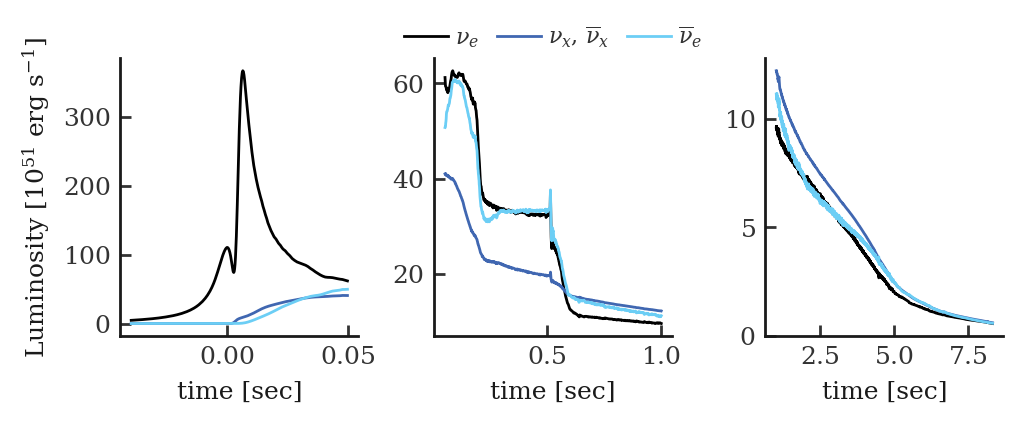

In [12]:
fig = plt.figure(figsize=(5,2))
ax1 = fig.add_subplot(1,3,1)
ax2 = fig.add_subplot(1,3,2)
ax3 = fig.add_subplot(1,3,3)

tmask1 = (sm.model.time.value > -0.04) & (sm.model.time.value <= 0.05)
tmask2 = (sm.model.time.value <= 1) & (sm.model.time.value > 0.05)
tmask3 = sm.model.time.value > 1

for f in Flavor:
    if f == Flavor.NU_X_BAR:
        continue
    for i, (ax, tm) in enumerate(zip([ax1, ax2, ax3], [tmask1, tmask2, tmask3])):
        label = f.to_tex()
        if f == Flavor.NU_X:
            label = r"$\nu_x$, $\overline{\nu}_x$"            
        ax.plot(sm.model.time[tm], 1e-51*sm.model.luminosity[f][tm], lw=1, label=label)
        ax.set(xlabel=r'time [sec]', ylabel='')
        ax.grid(False);

ax1.set(xlabel=r'time [sec]', ylabel=fr'Luminosity [$10^{{51}}$ erg s$^{{-1}}$]')
ax2.legend(ncol=3);

(0.001, 10)

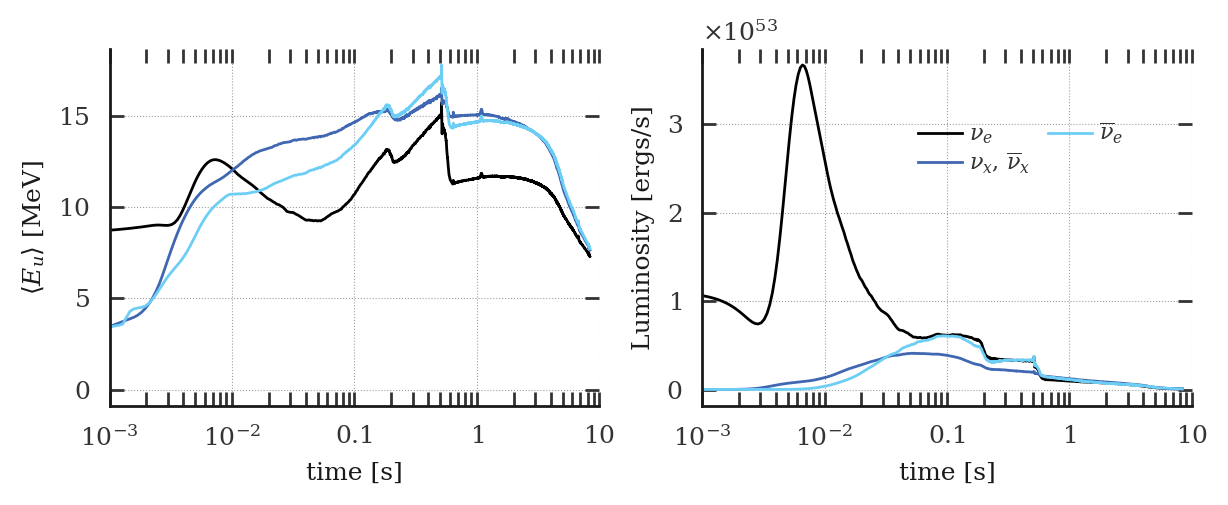

In [13]:
fig, (ax1, ax2) = hm.get_figax("double")

for i, f in enumerate(Flavor):
    if f == Flavor.NU_X_BAR:
        continue
    label = f.to_tex()
    if f == Flavor.NU_X:
        label = r"$\nu_x$, $\overline{\nu}_x$"
    ax1.semilogx(sm.model.time, sm.model.meanE[f], label=label)
    ax2.semilogx(sm.model.time, sm.model.luminosity[f], label=label)
    
ax1.set_ylabel(r"$\langle E_{u}\rangle$ [MeV]"); ax1.set_xlabel("time [s]")
ax1.set_xlim(1e-3,10)
ax2.set_ylabel("Luminosity [ergs/s]"); ax2.set_xlabel("time [s]")
ax2.legend(ncol=2, bbox_to_anchor=(0.65, 0.62));
ax2.set_xlim(1e-3,10)

In [14]:
tvals = np.logspace(-1, np.log10(sm.model.time[-1].value), 6)
Enu_vals = np.linspace(0,40,100)*u.MeV
ispec_t = sm.model.get_initial_spectra(50*u.ms, Enu_vals)
fluxunit = ispec_t[Flavor.NU_E].unit

# for different times, it does not work, so we tweak
# notice, the times are way too much, so we sparse it
_times = sm.model.time #[::20]
# construct a dictionary containing each {flavorname-array} pairs for each flavor
ispec_E = {f:np.zeros(len(_times))*fluxunit for f in Flavor}
for i, t in tqdm(enumerate(_times), total=len(_times)):
    temp = sm.model.get_initial_spectra(t, 5*u.MeV)
    for f in Flavor:
        ispec_E[f][i] = temp[f]

  0%|          | 0/9850 [00:00<?, ?it/s]

/home/melih/.local/lib/python3.9/site-packages/snewpy/models/base.py:305: RuntimeWarning: divide by zero encountered in log
  np.exp(np.log(L) - (2+a)*np.log(Ea) + (1+a)*np.log(1+a)
/home/melih/.local/lib/python3.9/site-packages/snewpy/models/base.py:305: RuntimeWarning: invalid value encountered in subtract
  np.exp(np.log(L) - (2+a)*np.log(Ea) + (1+a)*np.log(1+a)
/home/melih/.local/lib/python3.9/site-packages/snewpy/models/base.py:306: RuntimeWarning: divide by zero encountered in divide
  - loggamma(1+a) + a*np.log(E) - (1+a)*(E/Ea)) / (u.erg * u.s)


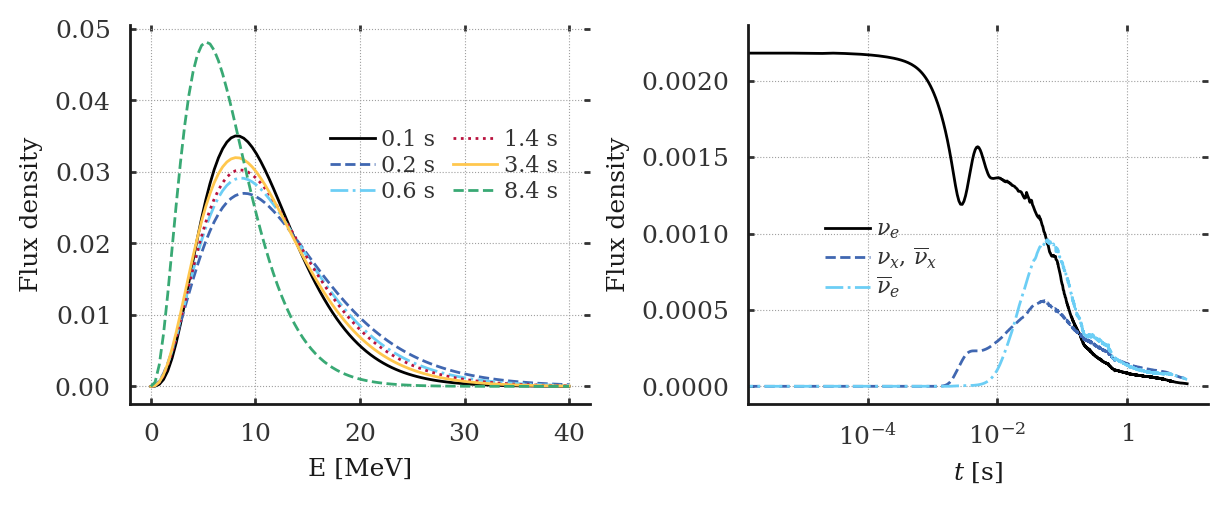

In [15]:
fig, (ax1, ax2) = hm.get_figax("double", tick_len=2) #plt.subplots(ncols=2, figsize=(9,4))
f = Flavor.NU_E

for i, t in enumerate(tvals):
    ispec_t = sm.model.get_initial_spectra(t*u.s, Enu_vals) # init spect, oscillated possible
    p = ax1.plot(Enu_vals, ispec_t[f]/np.sum(ispec_t[f]), label=fr'{t:.1f} s', 
                 linestyle=line_styles[i % len(line_styles)], lw=1, ) #color=xenon_cmap[i])# color=mpl.cm.jet(np.linspace(0,1,6))[i])
    ax1.set(xlabel=fr'E [{Enu_vals.unit}]', ylabel=fr'Flux density')
    ax1.grid(True);
    ax1.legend(loc='upper right', ncol=2, bbox_to_anchor=(0.95, 0.75));

# ax2.set_title(fr"Time distribution of $\nu_\beta$ with E$_{{\nu_\beta}}=5$ MeV")
for i, f in enumerate(Flavor):
    if f == Flavor.NU_X_BAR:
        continue
    label = f.to_tex()
    if f == Flavor.NU_X:
        label = r"$\nu_x$, $\overline{\nu}_x$"
    ax2.plot(_times, ispec_E[f]/np.sum(ispec_E[f]), label=label, ls=["-","--", "-.", ":"][i], ) #color=xenon_cmap[i])
ax2.set(xlabel=fr'$t$ [{_times.unit}]', ylabel=fr'Flux density')
ax2.legend(bbox_to_anchor=(0.29, 0.25), ncol=1)
ax2.grid(True)
ax2.set_xscale('log');

In [16]:
flux_single = sm.model.get_initial_spectra(1*u.s, 100*u.MeV, flavors=[Flavor.NU_E])
snewpy_unit_bases = [u.MeV, u.m, u.s, u.kg]
# flux_single[Flavor.NU_E].decompose(snewpy_unit_bases)
_scaled_fluxes = sm.scale_fluxes(10*u.kpc)
scaled_fluxes = {k:(v/(4.6e27 * u.count / u.tonne)).to(1/(u.MeV*u.s*u.m**2)) for k,v in _scaled_fluxes.items()}
# print(scaled_fluxes[Flavor.NU_E].unit)

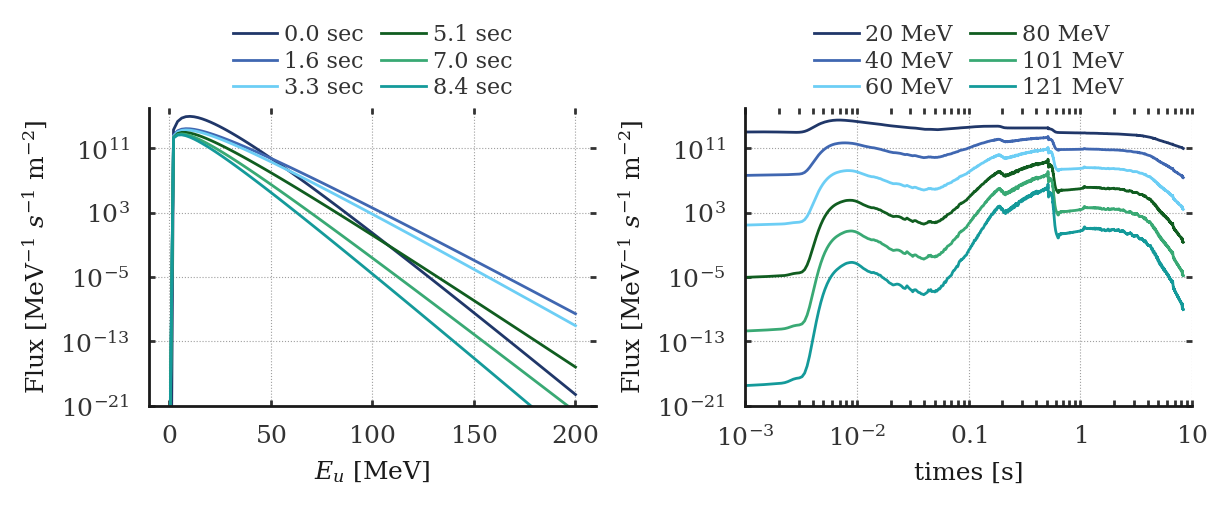

In [17]:
fig, (ax1, ax2) = hm.get_figax("double", tick_len=2)
a = iter(xenon_cmap)
for i in np.linspace(500,scaled_fluxes[Flavor.NU_E].shape[0]-1,6).astype(int):
    val = scaled_fluxes[Flavor.NU_E][i,:]
    ax1.semilogy(sm.neutrino_energies, val, label=f"{sm.times[i].value:.1f} sec", color=next(a));
    ax1.set_xlabel(r"$E_u$ [MeV]"); ax1.set_ylabel(r"Flux [MeV$^{-1}~s^{-1}~$m$^{-2}$]")
    ax1.set_ylim(1e-21, 1e16)
    ax1.legend()
    
a = iter(xenon_cmap)
for j in range(10, 70, 10):
    val = scaled_fluxes[Flavor.NU_E][:,j]
    ax2.loglog(sm.times, val, label=f"{int(sm.neutrino_energies[j].value)} MeV", color=next(a));
    ax2.set_xlabel("times [s]"); ax2.set_ylabel(r"Flux [MeV$^{-1}~s^{-1}~$m$^{-2}$]")
    ax2.set_ylim(1e-21, 1e16)
    ax2.set_xlim(1e-3,10)
ax2.legend();

# The Target

These are the properties of the interaction target

In [18]:
from snax.Nucleus import Target
from snax.Xenon_Atom import ATOM_TABLE
 ## For now, Argon is manually 
Ar36 = {
    'Type'		: 'Ar36',
    'MassNum'	: 36,
    'AtomicNum'	: 18,
    'Mass'		: 35.967545105,
    'Spin'		: 0,
    'Fraction'	: 3.336e-3
}

Ar38 = {
    'Type'		: 'Ar38',
    'MassNum'	: 38,
    'AtomicNum'	: 18,
    'Mass'		: 37.962732,
    'Spin'		: 0,
    'Fraction'	: 6.29E-4
}

Ar40 = {
    'Type'		: 'Ar40',
    'MassNum'	: 40,
    'AtomicNum'	: 18,
    'Mass'		: 39.962383,
    'Spin'		: 0,
    'Fraction'	: 0.996035
}

ATOM_TABLE_Ar = {
    'Ar36'	: Ar36,
    'Ar38'	: Ar38,
    'Ar40'	: Ar40,
}

Target we load {'Type': 'Xe131', 'MassNum': 131, 'AtomicNum': 54, 'Mass': 130.90508406, 'Spin': 1.5, 'Fraction': 0.212324}


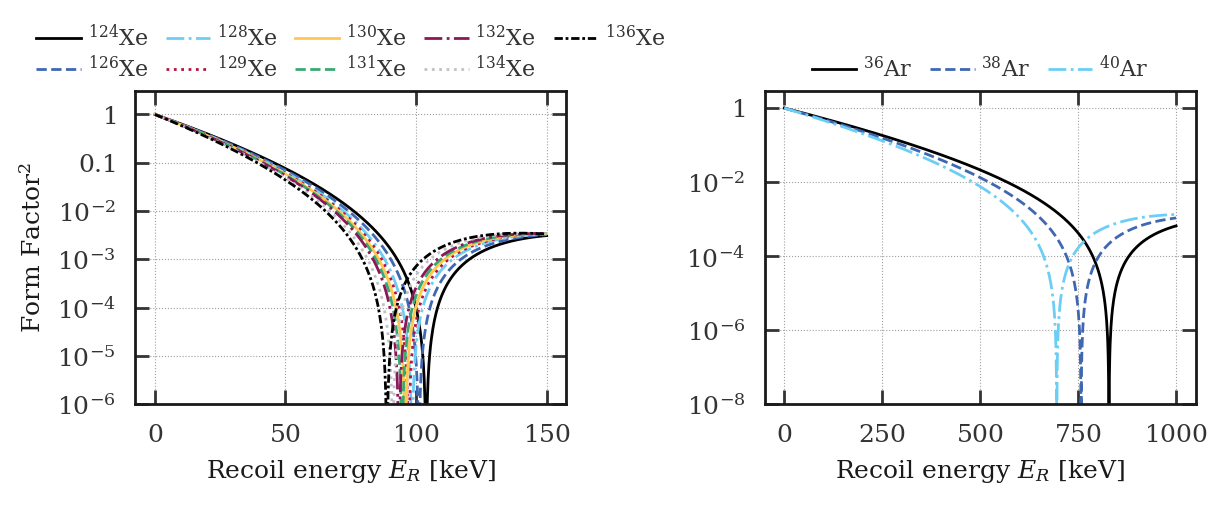

In [19]:
fig, axes = hm.get_figax("double", sharey=True) # plt.subplots(ncols=1, figsize=(9,5))
ax1, ax2 = axes

print("Target we load", ATOM_TABLE['Xe131'])
recoil_enXe = np.linspace(0,150,5000) * u.keV
neutrino_en = sm.neutrino_energies

for i, (k,v) in enumerate(ATOM_TABLE.items()):
    _singleXe = Target(v, pure=True) # pure means setting the abundance to =1    
    formfac = _singleXe.form_factor(np.linspace(0,150,500) * u.keV)
    crosssec = _singleXe.nN_cross_section(neutrino_en, recoil_enXe)
    val = _singleXe.name.split('Xe')[1]
    label = f"$^{{{val}}}\mathrm{{Xe}}$"
    ax1.semilogy(np.linspace(0,150,500) * u.keV, formfac**2, label=label, linestyle=line_styles[i % len(line_styles)], lw=1);
ax1.set_xlabel(fr'Recoil energy $E_R$ [{recoil_enXe.unit}]')
ax1.set_ylabel(r'Form Factor$^2$')
ax1.legend(ncol=5);
ax1.minorticks_off()
ax1.set_ylim(1e-6, None)
ax1.spines['top'].set_visible(True)
ax1.spines['right'].set_visible(True)
ax2.spines['top'].set_visible(True)
ax2.spines['right'].set_visible(True)

recoil_enAr =  np.linspace(0,1000,1000) * u.keV
for i, (k,v) in enumerate(ATOM_TABLE_Ar.items()):
    singleAr = Target(v, pure=True) # pure means setting the abundance to =1    
    formfacAr = singleAr.form_factor(recoil_enAr)
    crosssecAr = singleAr.nN_cross_section(neutrino_en, recoil_enAr)
    val = singleAr.name.split('Ar')[1]
    label = f"$^{{{val}}}\mathrm{{Ar}}$"
    ax2.semilogy(recoil_enAr, formfacAr**2, label=label, linestyle=line_styles[i % len(line_styles)], lw=1);
ax2.set_xlabel(fr'Recoil energy $E_R$ [{recoil_enAr.unit}]')
ax2.legend(ncol=5);
ax2.set_ylim(1e-8, None);

Cross sections with neutrinos of different energies. 

(1e-06, 5000.0)

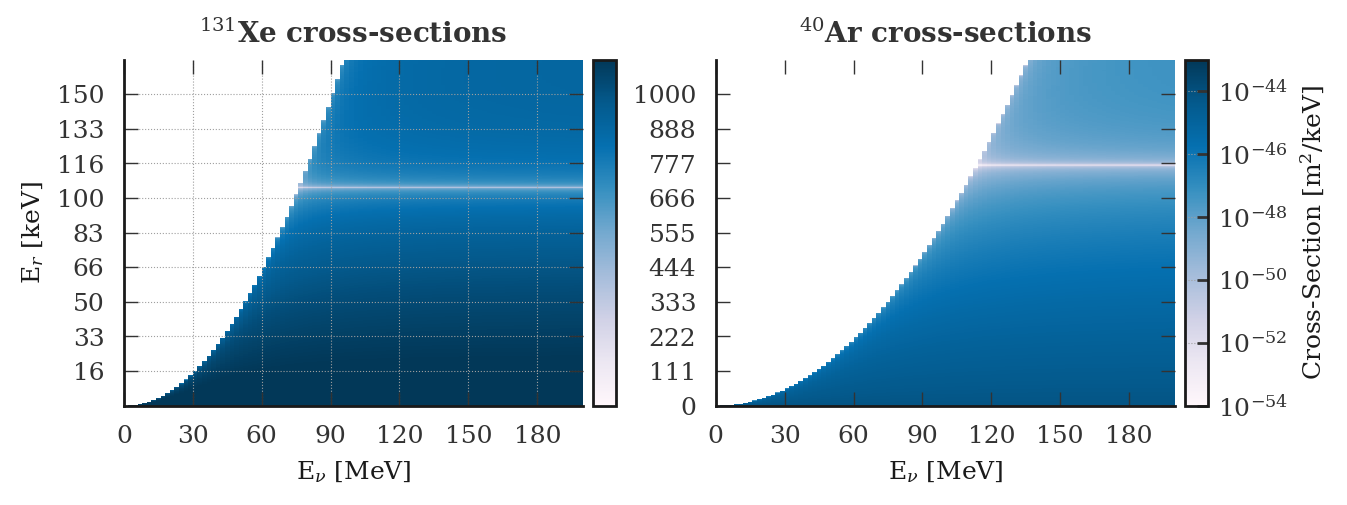

In [20]:
singleAr = Target(ATOM_TABLE_Ar['Ar40'], pure=True) # pure means setting the abundance to =1    
crosssecAr = singleAr.nN_cross_section(neutrino_en, recoil_enAr)

singleXe = Target(ATOM_TABLE['Xe131'], pure=True) # pure means setting the abundance to =1 
crosssecXe = singleXe.nN_cross_section(neutrino_en, recoil_enXe)

fig, (ax1, ax2) = hm.get_figax('double', tick_width=0.5) 
ax1.set_title(r"$^{131}$Xe cross-sections")
im = ax1.pcolormesh(crosssecXe.value, cmap='PuBu', norm=LogNorm(1e-54, 1e-43))
divider = make_axes_locatable(ax1)
cax1 = divider.append_axes('right', size='5%', pad=0.05)
cb = fig.colorbar(im, cax=cax1, orientation='vertical')
cb.set_ticks([])
# cb.set_label(r"Cross-Section [m$^2/$keV]")
ax1.set_xlabel(r'E$_\nu$ [MeV]',) # fontsize=16)
ax1.set_ylabel(r'E$_r$ [keV]',) # fontsize=16)
ax1.set_xticks(ticks=np.arange(0, crosssecXe.shape[1], 15), labels=np.arange(0, 100, 15, dtype=int)*2)
ax1.set_yticks(ticks=np.arange(0, crosssecXe.shape[0], crosssecXe.shape[0]/10), labels=np.linspace(0, recoil_enXe[-1].value, 10, dtype=int));

ax2.set_title(r"$^{40}$Ar cross-sections")
ax2.grid(False)
im = ax2.pcolormesh(crosssecAr.value, cmap='PuBu', norm=LogNorm(1e-54, 1e-43))
divider = make_axes_locatable(ax2)
cax = divider.append_axes('right', size='5%', pad=0.05)
cb = fig.colorbar(im, cax=cax, orientation='vertical',)
cb.set_label(r"Cross-Section [m$^2/$keV]")
ax2.set_xlabel(r'E$_\nu$ [MeV]',) # fontsize=16)
# ax2.set_ylabel(r'E$_r$ [keV]',) # fontsize=16)
ax2.set_xticks(ticks=np.arange(0, crosssecAr.shape[1], 15), labels=np.arange(0, 100, 15, dtype=int)*2)
ax2.set_yticks(ticks=np.arange(0, crosssecAr.shape[0], crosssecAr.shape[0]/10), labels=np.linspace(0, recoil_enAr[-1].value, 10, dtype=int));
ax1.set_ylim(1e-6,None)

# Interactions

The neutrino flux, interacts with the target. We compute the total differential interaction rates. 
The rates are also scaled for the volume and for the distance. Which can be easily changed. 

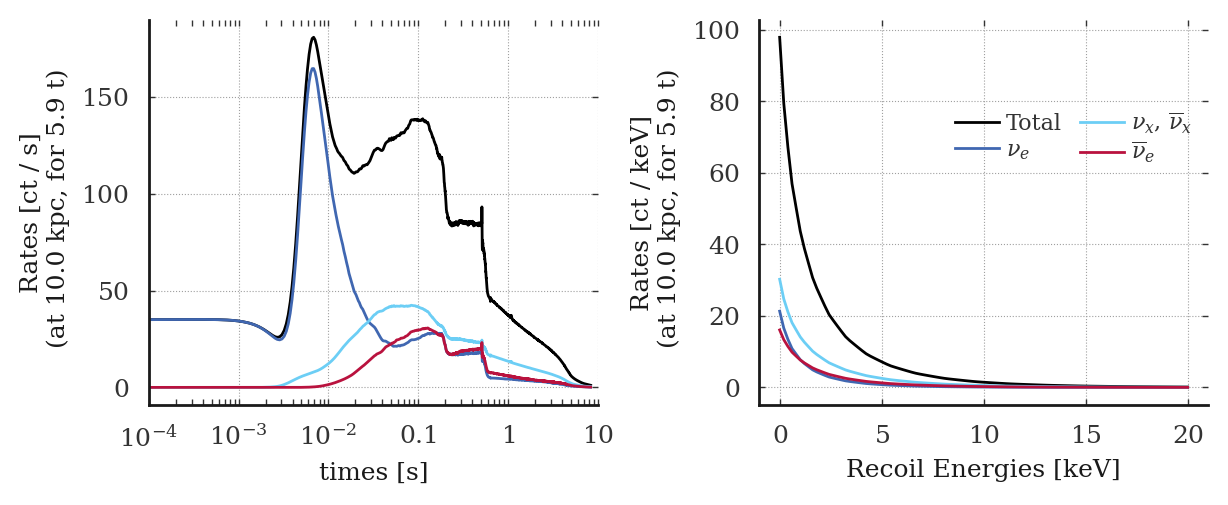

In [21]:
rates_time = interaction.rates_per_time_scaled
rates_recoil = interaction.rates_per_recoil_scaled
d = f"{interaction.distance.value} {interaction.distance.unit}"
v = f"{interaction.volume.value} {interaction.volume.unit}"

# plot the rates
fig, (ax1, ax2) = hm.get_figax("double", tick_width=0.5, tick_len=2) 
ax1.semilogx(interaction.Model.times, rates_time["Total"], )
ax2.plot(interaction.recoil_energies, rates_recoil["Total"], label="Total")
for f in Flavor:
    if f == Flavor.NU_X_BAR:
        continue
    label = f.to_tex()
    if f == Flavor.NU_X:
        label = r"$\nu_x$, $\overline{\nu}_x$"
    ax1.semilogx(interaction.Model.times, rates_time[f])
    ax2.plot(interaction.recoil_energies, rates_recoil[f], label=label)

ax1.set_xlim(1e-4,10)
ax1.set_ylabel(f"Rates [{rates_time['Total'].unit}]\n (at {d}, for {v})")
ax1.set_xlabel(f"times [{interaction.Model.times.unit}]")
ax2.set_ylabel(f"Rates [{rates_recoil['Total'].unit}]\n (at {d}, for {v})")
ax2.set_xlabel(f"Recoil Energies [{interaction.recoil_energies.unit}]")
ax2.legend(bbox_to_anchor=(0.7,.6));

#### Scaling

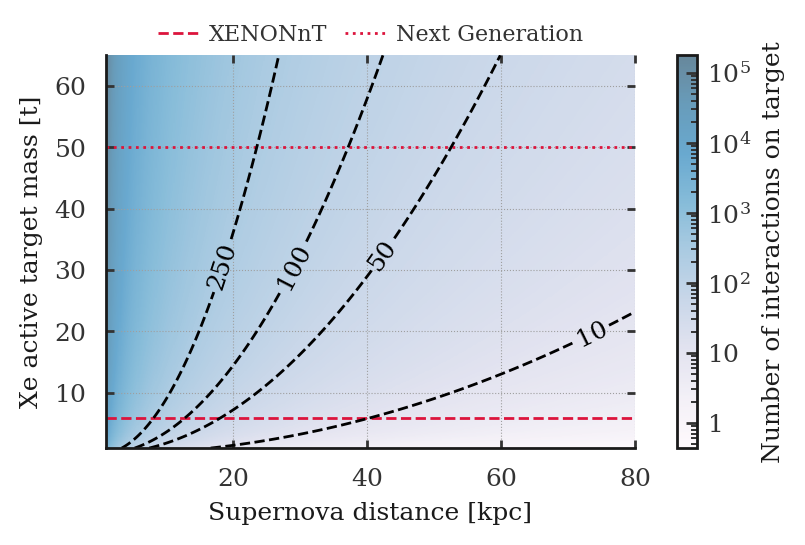

In [24]:
def get_mass(d, N):
    return N*d**2/2730.788102680283

def get_counts(d, m):
    # counts for 1t at 1kpc
    _c = 2761.2438 # kpc^2 ct / t
    return(m*_c/d**2)

def fmt(x):
    return f'{int(x)}'

_ds = np.linspace(1,80,500)
_m = np.linspace(1,65,500)
_xx,_yy = np.meshgrid(_ds, _m)
_zz = get_counts(_xx, _yy)

fig, ax = hm.get_figax() # plt.subplots(1,1,figsize = (8,6))
ax.axhline(5.9, color='crimson', ls='--', label='XENONnT')
ax.axhline(50, color='crimson', ls=':', label='Next Generation')
cb = ax.pcolormesh(_ds, _m, _zz, cmap='PuBu', alpha=0.6, norm = LogNorm()) #  afmhot_r
contours = ax.contour(_xx,_yy,_zz, [10, 50, 100, 250], colors = 'k', linestyles = '--')
manual_locations = [(20,30),(30,30),(45,30), (70,30)]

ax.clabel(contours, contours.levels, inline=True, 
        fmt = fmt, manual = manual_locations, 
        fontsize = 9, use_clabeltext=True)

ax.set_ylabel('Xe active target mass [t]')
ax.set_xlabel('Supernova distance [kpc]')
ax.legend()
fig.colorbar(cb, label='Number of interactions on target');

# Total Rates

Now without any selection or detector effects, we compute the expected totals (simply the integration of the Total curves) at 10 kpc for 5.9 tons

In [25]:
interaction.expected_total

{<Flavor.NU_E: 0>: <Quantity 26.1396262 ct>,
 <Flavor.NU_X: 1>: <Quantity 54.14300035 ct>,
 <Flavor.NU_E_BAR: 2>: <Quantity 28.48775543 ct>,
 <Flavor.NU_X_BAR: 3>: <Quantity 54.14300035 ct>,
 'Total': <Quantity 162.91338234 ct>}

### Collect all models

In [26]:
def load_snax_models(model_name, indices):
    snax_models = {}
    for ii in indices:
        model = loader.get_model(model_name, combination_index=ii)
        model = SnaxModel(model)
        model.compute_model_fluxes()

        # Interactions with the xenon target
        interaction = Interactions(model, Nuclei="Xenon", isotope="mix")
        interaction.compute_interaction_rates()
        interaction.scale_rates(distance=10, volume=5.9)

        snax_models[f'{model_name.lower()}_snax_{ii}'] = interaction

    return snax_models


# Selected indices for each model
selected_bollig_indices = [1, 2]
selected_nakazato_indices = [2, 13, 14, 15, 20]
selected_fornax_indices = [2, 15]
selected_sukhbold_indices = [1, 2, 3, 4]

# Load models
bollig_snax_models = load_snax_models('Bollig_2016', selected_bollig_indices)
nakazato_snax_models = load_snax_models('Nakazato_2013', selected_nakazato_indices)
fornax_snax_models = load_snax_models('Fornax_2021', selected_fornax_indices)
sukhbold_snax_models = load_snax_models('Sukhbold_2015', selected_sukhbold_indices)

>>>>> sn_Bollig_2016_u4yy22k2l4.pkl
> Retrieving object self.proc_locsn_Bollig_2016_u4yy22k2l4.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
> Retrieving object self.proc_loc/sn_Bollig_2016_u4yy22k2l4_interaction_Xenon_mix.pkl


  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

> Computed the total rates at the source for 1 atom (not scaled)
>>>>> sn_Bollig_2016_vkoba6ydqy.pkl
> Retrieving object self.proc_locsn_Bollig_2016_vkoba6ydqy.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
> Retrieving object self.proc_loc/sn_Bollig_2016_vkoba6ydqy_interaction_Xenon_mix.pkl


  0%|          | 0/9 [00:00<?, ?it/s]

...

  0%|          | 0/9 [00:00<?, ?it/s]

> Computed the total rates at the source for 1 atom (not scaled)
>>>>> sn_Sukhbold_2015_pmmxngkvej.pkl
> Retrieving object self.proc_locsn_Sukhbold_2015_pmmxngkvej.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
> Retrieving object self.proc_loc/sn_Sukhbold_2015_pmmxngkvej_interaction_Xenon_mix.pkl


  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

> Computed the total rates at the source for 1 atom (not scaled)


In [27]:
mymodels = [bollig_snax_models, sukhbold_snax_models, fornax_snax_models, nakazato_snax_models]
model_names = ['Bollig', 'Sukhbold', 'Fornax', 'Nakazato']

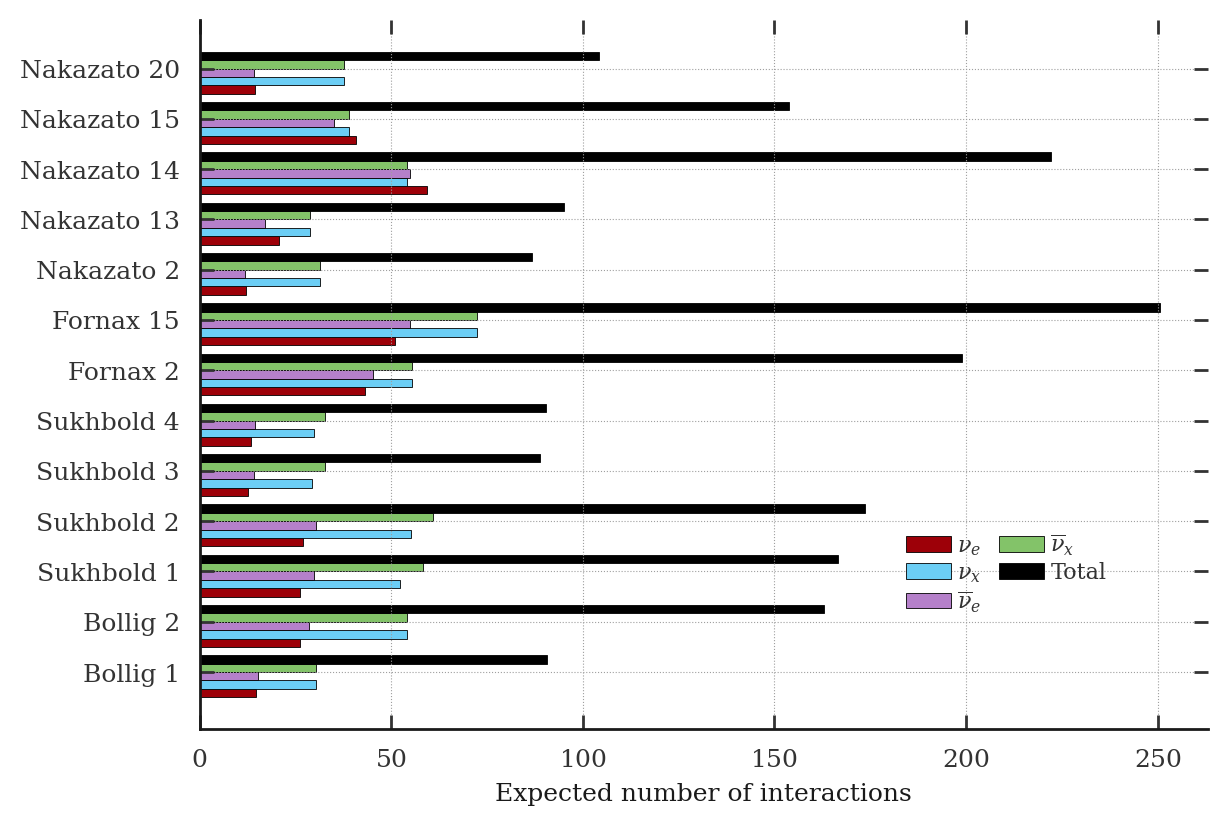

In [28]:
fig, ax = hm.get_figax("single long")

bar_height = 2
space_between_models = 2
y_offset = 0
model_name_positions = []
model_name_labels = []

for model_name, model_dict in zip(model_names, mymodels):
    for j, (model_key, model) in enumerate(model_dict.items()):
        y_pos = np.arange(len(model.expected_total)) * bar_height + y_offset
        if model_key=='bollig_2016_snax_1':
            legend_labels = [k.to_tex() if k!="Total" else "Total" for k in model.expected_total.keys()]
        else:
            legend_labels = None
        ax.barh(y_pos, [i.value for i in model.expected_total.values()], bar_height, label=legend_labels, ec='k', lw=0.3, 
                color=['k', xps.colors['1sigma_green'], xps.colors['violet'], xps.colors['xenon_lightblue'], xps.colors['darkred']][::-1])
        model_name_positions.append(y_offset + (len(model.expected_total) * bar_height) / 2)
        _l = f"{model_name} {model_key.split('_')[-1]}"
        model_name_labels.append(_l)
        y_offset += len(model.expected_total) * bar_height + space_between_models

ax.legend(ncols=2, bbox_to_anchor=(0.8, 0.15))
# # Adjust y-ticks and labels
y_ticks = np.arange(len(model.expected_total) * len(mymodels) * bar_height + len(mymodels) * space_between_models)
y_tick_labels = [f"{model_name} - {k}" for model_name in model_names for k in model.expected_total.keys()]
ax.set_yticks(model_name_positions)
ax.set_yticklabels(model_name_labels)
ax.set_xlabel('Expected number of interactions');

Let's make it slightly more realistic by adding a delta function energy threshold at 0.7 keV  

In [29]:
model_handles_indices = [
    (r"Bollig, 11.2 $M_\odot$", "Bollig_2016", 1),
    (r"Bollig, 27 $M_\odot$", "Bollig_2016", 2),
    (r"Nakazato, 13 $M_\odot$, 100 ms, 0.004 (shen)", "Nakazato_2013", 2),
    (r"Nakazato, 30 $M_\odot$, 0 ms, 0.004 (LS220)", "Nakazato_2013", 20),
    (r"Nakazato, 30 $M_\odot$, 0 ms, 0.004 (shen)", "Nakazato_2013", 13),
    (r"Nakazato, 30 $M_\odot$, 0 ms, 0.004 (togashi)", "Nakazato_2013", 14),
    (r"Nakazato, 50 $M_\odot$, 100 ms, 0.004 (shen)", "Nakazato_2013", 15),
    (r"Fornax, 13 $M_\odot$", "Fornax_2021", 2),
    (r"Fornax, 26.99 $M_\odot$", "Fornax_2021", 15),
    (r"Sukhbold, 27 $M_\odot$ (LS220)", "Sukhbold_2015", 1),
    (r"Sukhbold, 27 $M_\odot$ (SFHo)", "Sukhbold_2015", 2),
    (r"Sukhbold, 9.6 $M_\odot$ (LS220)", "Sukhbold_2015", 3),
    (r"Sukhbold, 9.6 $M_\odot$ (SFHo)", "Sukhbold_2015", 4)]

In [30]:
nakazato_snax_models.keys()

dict_keys(['nakazato_2013_snax_2', 'nakazato_2013_snax_13', 'nakazato_2013_snax_14', 'nakazato_2013_snax_15', 'nakazato_2013_snax_20'])

In [31]:
collected_interactions = {**sukhbold_snax_models, **bollig_snax_models, **fornax_snax_models, **nakazato_snax_models}

In [41]:
expectedcounts_07kev = {}
expectedcounts_0kev = {}

for tupl in model_handles_indices:
    label, model_base, k = tupl
    interaction = collected_interactions[model_base.lower()+f"_snax_{k}"]
    # all interactions 
    expectedcounts_0kev[label] = interaction.expected_total['Total'].value
    largerthanXkev_indices = np.where(interaction.recoil_energies.value > 0.7)[0]
    expected_total_above_07keV = np.trapz(interaction.rates_per_recoil_scaled['Total'][largerthanXkev_indices], 
                                          interaction.recoil_energies[largerthanXkev_indices])
    expectedcounts_07kev[label] = expected_total_above_07keV.value

In [42]:
expectedcounts_0kev

{'Bollig, 11.2 $M_\\odot$': 90.7316682593472,
 'Bollig, 27 $M_\\odot$': 162.91338233674531,
 'Nakazato, 13 $M_\\odot$, 100 ms, 0.004 (shen)': 86.63428386021329,
 'Nakazato, 30 $M_\\odot$, 0 ms, 0.004 (LS220)': 104.2390979865698,
 'Nakazato, 30 $M_\\odot$, 0 ms, 0.004 (shen)': 95.1733255113919,
 'Nakazato, 30 $M_\\odot$, 0 ms, 0.004 (togashi)': 222.22386030430752,
 'Nakazato, 50 $M_\\odot$, 100 ms, 0.004 (shen)': 153.78196417532632,
 'Fornax, 13 $M_\\odot$': 199.0289148255508,
 'Fornax, 26.99 $M_\\odot$': 250.60067002106288,
 'Sukhbold, 27 $M_\\odot$ (LS220)': 166.60426379168865,
 'Sukhbold, 27 $M_\\odot$ (SFHo)': 173.49210848624458,
 'Sukhbold, 9.6 $M_\\odot$ (LS220)': 88.87511872145679,
 'Sukhbold, 9.6 $M_\\odot$ (SFHo)': 90.49404700781541}

In [43]:
expectedcounts_07kev

{'Bollig, 11.2 $M_\\odot$': 56.27623446297311,
 'Bollig, 27 $M_\\odot$': 106.82153478462537,
 'Nakazato, 13 $M_\\odot$, 100 ms, 0.004 (shen)': 52.52301929160285,
 'Nakazato, 30 $M_\\odot$, 0 ms, 0.004 (LS220)': 63.63162607342331,
 'Nakazato, 30 $M_\\odot$, 0 ms, 0.004 (shen)': 73.88520593301305,
 'Nakazato, 30 $M_\\odot$, 0 ms, 0.004 (togashi)': 181.20021053762395,
 'Nakazato, 50 $M_\\odot$, 100 ms, 0.004 (shen)': 123.6942018148724,
 'Fornax, 13 $M_\\odot$': 144.16943069942647,
 'Fornax, 26.99 $M_\\odot$': 183.33885712423708,
 'Sukhbold, 27 $M_\\odot$ (LS220)': 107.31134664581819,
 'Sukhbold, 27 $M_\\odot$ (SFHo)': 110.48339255127604,
 'Sukhbold, 9.6 $M_\\odot$ (LS220)': 53.589183365227115,
 'Sukhbold, 9.6 $M_\\odot$ (SFHo)': 52.671012290181174}

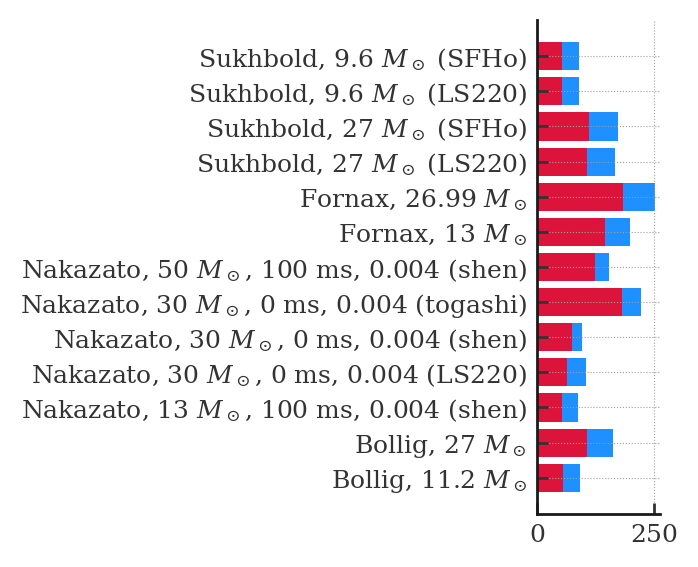

In [49]:
plt.barh(np.arange(13), list(expectedcounts_0kev.values()), color='dodgerblue')
plt.barh(np.arange(13), list(expectedcounts_07kev.values()), color='crimson')
plt.yticks(np.arange(13), list(expectedcounts_07kev.keys()));

## Notes

In [11]:
model_snax = loader.get_model("Bollig_2016", combination_index=2)
sm = SnaxModel(model_snax)
sm.compute_model_fluxes()

>>>>> sn_Bollig_2016_vkoba6ydqy.pkl
> Retrieving object self.proc_locsn_Bollig_2016_vkoba6ydqy.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.


In [12]:
selected_params.keys()

dict_keys(['Nakazato_2013', 'Bollig_2016', 'Fornax_2021', 'Sukhbold_2015'])

In [21]:
selected_params["Nakazato_2013"].index.values

array([ 2, 13, 14, 15, 20])

In [22]:
selected_params["Nakazato_2013"]

,progenitor_mass,revival_time,metallicity,eos,hash
Combination Index,,,,,
2,13.0 solMass,100.0 ms,0.004,shen,l5mq5h2vhm
13,30.0 solMass,0.0 ms,0.004,LS220,qhascq5ysp
14,30.0 solMass,0.0 ms,0.004,shen,rrzuqp7bnr
15,30.0 solMass,0.0 ms,0.004,togashi,36xv2hupfo
20,50.0 solMass,100.0 ms,0.004,shen,voh2e7fu46


>>>>> sn_Nakazato_2013_mxztg2jos6.pkl
> Retrieving object self.proc_locsn_Nakazato_2013_mxztg2jos6.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
Nakazato_2013 2


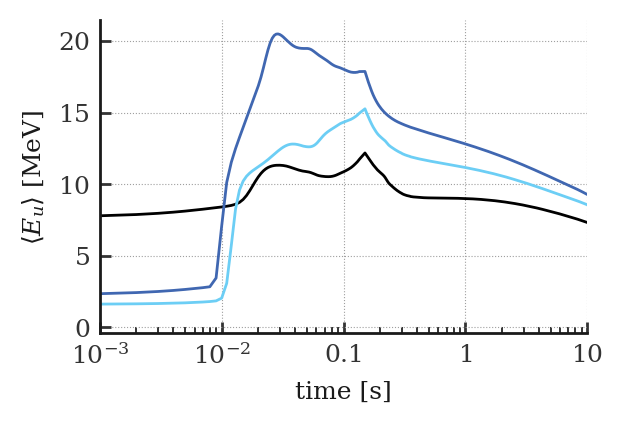

>>>>> sn_Nakazato_2013_teq5mqtdxh.pkl
> Retrieving object self.proc_locsn_Nakazato_2013_teq5mqtdxh.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
Nakazato_2013 13


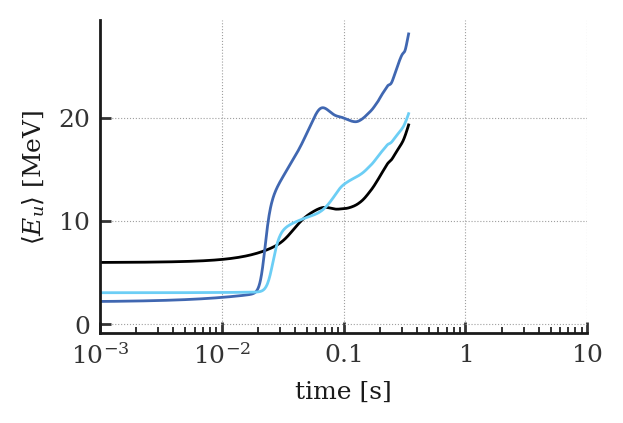

>>>>> sn_Nakazato_2013_3yldwwpuzp.pkl
> Retrieving object self.proc_locsn_Nakazato_2013_3yldwwpuzp.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
Nakazato_2013 14


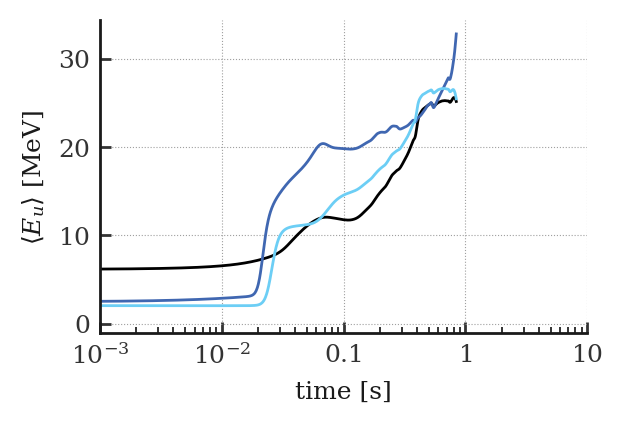

>>>>> sn_Nakazato_2013_vsoexmtcja.pkl
> Retrieving object self.proc_locsn_Nakazato_2013_vsoexmtcja.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
Nakazato_2013 15


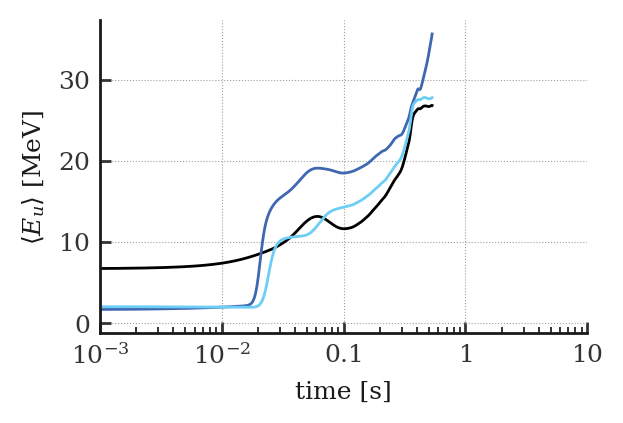

>>>>> sn_Nakazato_2013_wek4qx6bmh.pkl
> Retrieving object self.proc_locsn_Nakazato_2013_wek4qx6bmh.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
Nakazato_2013 20


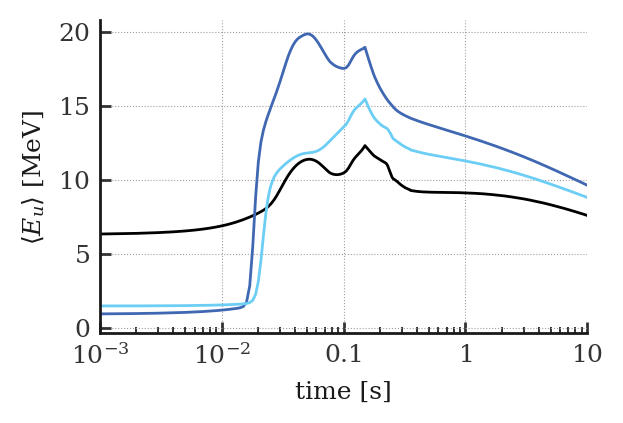

>>>>> sn_Bollig_2016_u4yy22k2l4.pkl
> Retrieving object self.proc_locsn_Bollig_2016_u4yy22k2l4.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
Bollig_2016 1


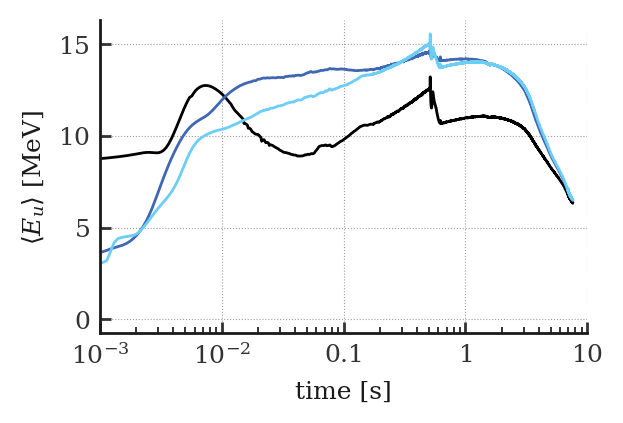

>>>>> sn_Bollig_2016_vkoba6ydqy.pkl
> Retrieving object self.proc_locsn_Bollig_2016_vkoba6ydqy.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
Bollig_2016 2


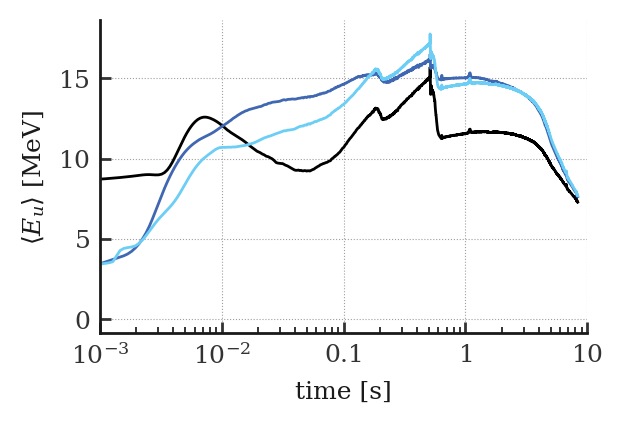

>>>>> sn_Fornax_2021_7vsdmxf6kv.pkl
> Retrieving object self.proc_locsn_Fornax_2021_7vsdmxf6kv.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
>>>Fornax_2021, 2
>>>>> sn_Fornax_2021_ijnlsmgm2c.pkl
> Retrieving object self.proc_locsn_Fornax_2021_ijnlsmgm2c.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
>>>Fornax_2021, 15
>>>>> sn_Sukhbold_2015_udwqbrabql.pkl
> Retrieving object self.proc_locsn_Sukhbold_2015_udwqbrabql.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
Sukhbold_2015 1


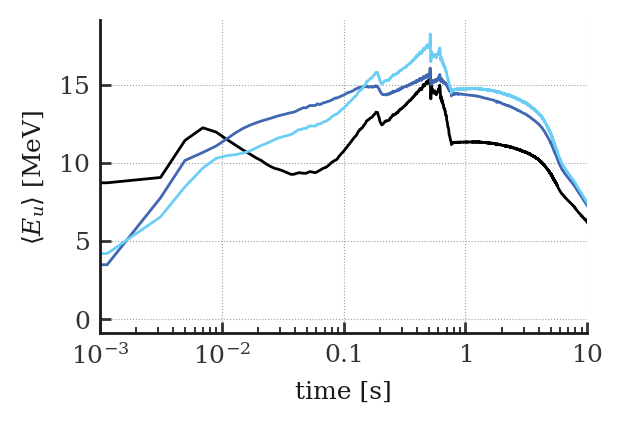

>>>>> sn_Sukhbold_2015_lxxhciobsf.pkl
> Retrieving object self.proc_locsn_Sukhbold_2015_lxxhciobsf.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
Sukhbold_2015 2


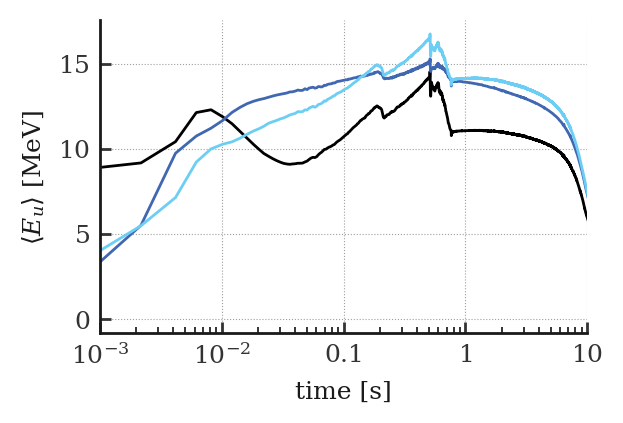

>>>>> sn_Sukhbold_2015_d5m2fyqfdh.pkl
> Retrieving object self.proc_locsn_Sukhbold_2015_d5m2fyqfdh.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
Sukhbold_2015 3


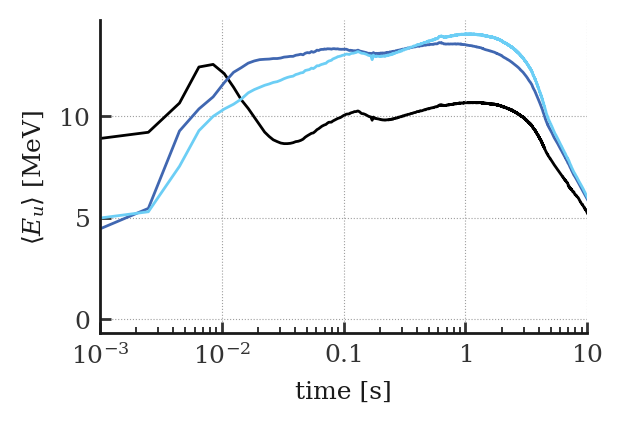

>>>>> sn_Sukhbold_2015_pmmxngkvej.pkl
> Retrieving object self.proc_locsn_Sukhbold_2015_pmmxngkvej.pkl
Fluxes already exist in `self.fluxes`, and force=False, doing nothing.
Sukhbold_2015 4


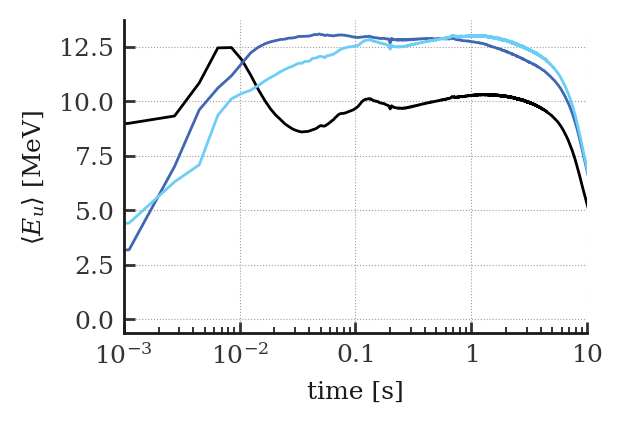

In [26]:
# for k,v in selected_params.items():
#     for ind in v.index.values:
#         model_snax = loader.get_model(k, combination_index=ind)
#         sm = SnaxModel(model_snax)
#         sm.compute_model_fluxes()
#         try:
#             sm.model.meanE
#         except:
#             print(f">>>{k}, {ind}")
#             continue
#         print(k, ind)
#         fig, ax = plt.subplots(figsize=(3,2))
        
#         for i, f in enumerate(Flavor):
#             if f == Flavor.NU_X_BAR:
#                 continue
#             label = f.to_tex()
#             if f == Flavor.NU_X:
#                 label = r"$\nu_x$, $\overline{\nu}_x$"
#             ax.semilogx(sm.model.time, sm.model.meanE[f], label=label)
    
#         ax.set_ylabel(r"$\langle E_{u}\rangle$ [MeV]"); ax.set_xlabel("time [s]")
#         ax.set_xlim(1e-3,10)
#         plt.savefig(f"../../thesis-plots/{k}_{ind}.png")
#         plt.show()